# Notebook 3 (máy local) – Trình bày kết quả và demo **OFFLINE**
**Đề tài 21 – ViTHSD** · Môn CMP169

Notebook này dùng khi **thuyết trình**, chạy trên máy cá nhân, **không cần Internet, không cần GPU**:
- nạp 2 mô hình ViSoBERT và PhoBERT-v2 **đã fine-tune** (thư mục `models/visobert`, `models/phobert` – do Notebook 2 trên máy tạo ra, hoặc giải nén `ViTHSD_ket_qua.zip` từ Colab);
- tái tạo baseline TF-IDF + Logistic Regression ngay trên máy (khoảng 1 phút);
- đánh giá lại cả 3 mô hình trên tập test, so với kết quả Colab và paper;
- demo dự đoán bình luận mới, đặt 3 mô hình cạnh nhau.

Ô đầu tiên **khóa kết nối mạng** của notebook: mọi lệnh cố truy cập Internet sẽ báo lỗi → chứng minh với thầy là chạy offline.

In [1]:
# ===== 1. Bật chế độ offline + KHÓA mạng (chạy ô này ĐẦU TIÊN) =====
import os, socket
os.environ["HF_HUB_OFFLINE"] = "1"          # thư viện Hugging Face không gọi Internet
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

def _blocked(*args, **kwargs):
    raise ConnectionError("Đã khóa Internet trong notebook này – mọi thứ phải chạy offline")
socket.socket.connect = _blocked            # chặn mọi kết nối mạng từ Python
socket.create_connection = _blocked

try:                                        # thử truy cập 1 trang web -> phải thất bại
    import urllib.request
    urllib.request.urlopen("https://huggingface.co", timeout=3)
    print("CẢNH BÁO: vẫn truy cập được Internet!")
except Exception as e:
    print("Kiểm tra mạng: KHÔNG truy cập được Internet ->", type(e).__name__, "| notebook chạy offline")

Kiểm tra mạng: KHÔNG truy cập được Internet -> URLError | notebook chạy offline


In [2]:
# ===== 2. Thư viện, kiểm tra các file cần thiết =====
import warnings; warnings.filterwarnings("ignore")
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
import torch
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()

import common
from common import TARGETS, LEVELS, OUT_DIR, MODEL_DIR
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODELS = {"visobert": "ViSoBERT", "phobert": "PhoBERT-v2"}

print("Thiết bị:", DEVICE)
for key in MODELS:
    ok = (MODEL_DIR / key / "model.safetensors").exists()
    print(f"  models/{key:9s}: {'OK' if ok else 'THIẾU – chạy Notebook 2 (hoặc giải nén ViTHSD_ket_qua.zip từ Colab)'}")
print("  outputs/ (kết quả Colab):", "OK" if (OUT_DIR / "baseline_info.json").exists() else "THIẾU – chạy Notebook 1 trước")

Thiết bị: cuda
  models/visobert : OK
  models/phobert  : OK
  outputs/ (kết quả Colab): OK


## 3. Dữ liệu (cùng file và cùng cách làm sạch như trên Colab)

In [3]:
train, dev, test, clean_report = common.load_and_clean()
Ytr, Yte = common.label_matrix(train), common.label_matrix(test)
display(pd.DataFrame([clean_report]))

Train: 7000 -> 6785 dòng (bỏ 4 dòng lỗi, 76 dòng trùng, 135 dòng trùng với dev/test) | dev 1201 | test 1800


,train_goc,bo_dong_loi,bo_trung_hoan_toan,bo_trung_dev_test,train_con_lai,dev,test
0,7000,4,76,135,6785,1201,1800


## 4. Baseline TF-IDF + Logistic Regression
Huấn luyện lại trên máy với **đúng siêu tham số đã chọn trên Colab** (đọc từ `outputs/baseline_info.json`). Chỉ fit trên train.

In [4]:
info_path = OUT_DIR / "baseline_info.json"
binfo = json.loads(info_path.read_text(encoding="utf-8")) if info_path.exists() else {"best_C": 1.0, "best_class_weight": "balanced"}
C, CW = binfo["best_C"], (None if binfo["best_class_weight"] in ("None", "none") else binfo["best_class_weight"])
t0 = time.time()
vec = common.build_vectorizer()
Xtr = vec.fit_transform(train["text"])
lr_models = common.fit_lr(Xtr, Ytr, C, CW)
print(f"Đã huấn luyện baseline (C={C}, class_weight={CW}) trong {time.time() - t0:.0f} giây")

def predict_baseline(texts):
    probs = common.predict_proba_lr(lr_models, vec.transform([common.normalize_text(t) for t in texts]))
    return probs.argmax(-1), probs

Đã huấn luyện baseline (C=1.0, class_weight=balanced) trong 10 giây


## 5. Nạp 2 mô hình Transformer đã fine-tune (chỉ đọc ổ đĩa)

In [5]:
loaded = {}
segmenter = common.make_segmenter()          # tách từ cho PhoBERT (underthesea, offline)
for key, name in MODELS.items():
    path = MODEL_DIR / key
    if not (path / "model.safetensors").exists():
        print(f"Bỏ qua {name}: chưa có {path}")
        continue
    model, tok, info = common.load_finetuned(path, DEVICE)
    loaded[key] = (model, tok, info)
    print(f"{name:11s}: {sum(p.numel() for p in model.parameters())/1e6:.1f} triệu tham số | "
          f"epoch tốt nhất {info.get('best_epoch')} | ngưỡng {info.get('threshold')} | tách từ: {info.get('segment')}")

ViSoBERT   : 97.6 triệu tham số | epoch tốt nhất 4 | ngưỡng 0.25 | tách từ: False
PhoBERT-v2 : 135.0 triệu tham số | epoch tốt nhất 6 | ngưỡng 0.3 | tách từ: True


## 6. Đánh giá lại trên tập test (offline) và so với kết quả lúc train
Trên CPU mỗi mô hình mất khoảng 1–3 phút cho 1.800 bình luận.

In [6]:
texts = test["content"].tolist()
results, preds = {}, {}
t0 = time.time()
preds["TF-IDF + LR"] = predict_baseline(texts)
for key, (model, tok, info) in loaded.items():
    t1 = time.time()
    preds[MODELS[key]] = common.predict_transformer(model, tok, info, texts, device=DEVICE, segmenter=segmenter)
    print(f"{MODELS[key]}: dự đoán xong trong {time.time() - t1:.0f} giây")
for name, (p, pr) in preds.items():
    results[name] = common.summarize(p, Yte, pr)
table = pd.DataFrame(results).T
display(table)

# Đối chiếu với con số đã tính trên Colab (phải gần như trùng)
colab = {MODELS[k]: loaded[k][2]["test"]["F1 T+L micro"] for k in loaded}
if (OUT_DIR / "baseline_test_results.csv").exists():
    colab["TF-IDF + LR"] = pd.read_csv(OUT_DIR / "baseline_test_results.csv", index_col=0).loc["TF-IDF + LR", "F1 T+L micro"]
display(pd.DataFrame({"F1 T+L micro – local (offline)": table["F1 T+L micro"], "F1 T+L micro – lúc train": pd.Series(colab)}))

ViSoBERT: dự đoán xong trong 2 giây
PhoBERT-v2: dự đoán xong trong 3 giây


,F1 T+L micro,P T+L micro,R T+L micro,F1 Target micro,F1 T+L (paper),F1 Target (paper),Macro-F1 TB 5 target,Toxic F1,Toxic ROC-AUC,Toxic PR-AUC,Recall hate
TF-IDF + LR,51.96,48.84,55.50,73.81,48.51,69.46,42.51,78.65,85.78,85.51,70.49
ViSoBERT,55.63,53.36,58.09,75.01,51.56,71.78,38.07,78.65,85.19,84.18,69.10
PhoBERT-v2,55.25,52.89,57.84,71.71,49.21,66.27,38.54,79.63,86.77,86.09,69.62


,F1 T+L micro – local (offline),F1 T+L micro – lúc train
PhoBERT-v2,55.25,55.25
TF-IDF + LR,51.96,51.96
ViSoBERT,55.63,55.67


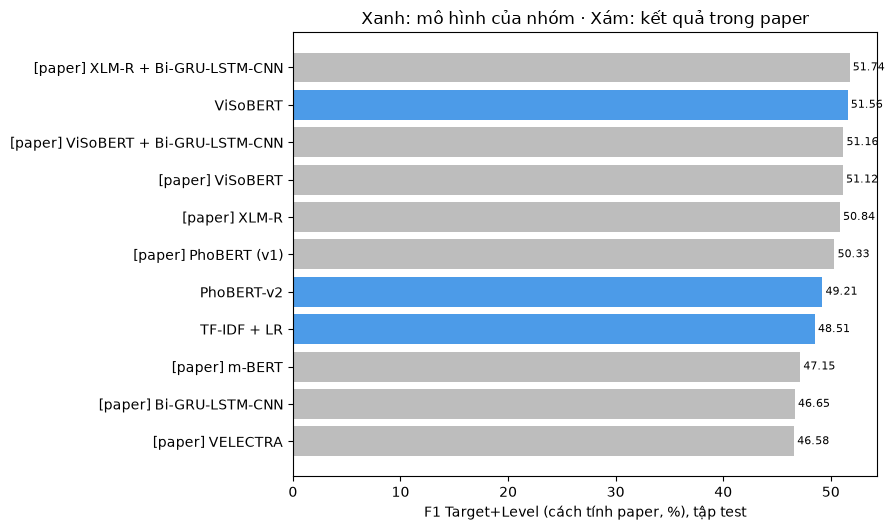

Mô hình tốt nhất: ViSoBERT


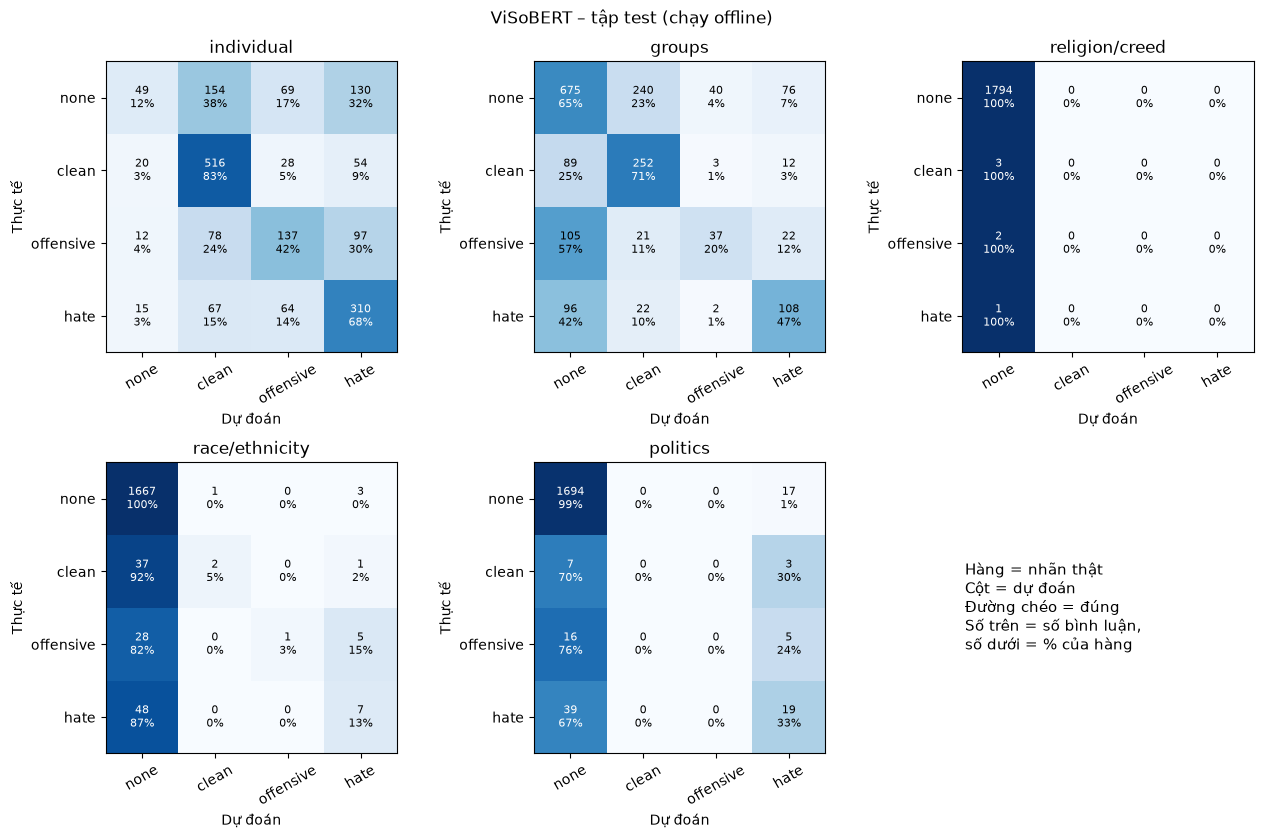

In [7]:
# So sánh với paper (F1 Target+Level theo cách tính của tác giả)
allr = {**{f"[paper] {k}": v for k, v in common.PAPER_RESULTS.items()}, **table["F1 T+L (paper)"].to_dict()}
names = sorted(allr, key=allr.get)
fig, ax = plt.subplots(figsize=(9, 0.4 * len(names) + 1))
ax.barh(names, [allr[n] for n in names], color=["#bdbdbd" if n.startswith("[paper]") else "#4c9be8" for n in names])
for i, n in enumerate(names):
    ax.text(allr[n] + 0.3, i, f"{allr[n]:.2f}", va="center", fontsize=8)
ax.set_xlabel("F1 Target+Level (cách tính paper, %), tập test"); ax.set_title("Xanh: mô hình của nhóm · Xám: kết quả trong paper")
plt.tight_layout(); plt.show()

best = table["F1 T+L micro"].idxmax()
print("Mô hình tốt nhất:", best)
common.plot_confusion_matrices(preds[best][0], Yte, f"{best} – tập test (chạy offline)"); plt.show()

## 7. Biểu đồ quá trình huấn luyện (learning curve)

**ViSoBERT**

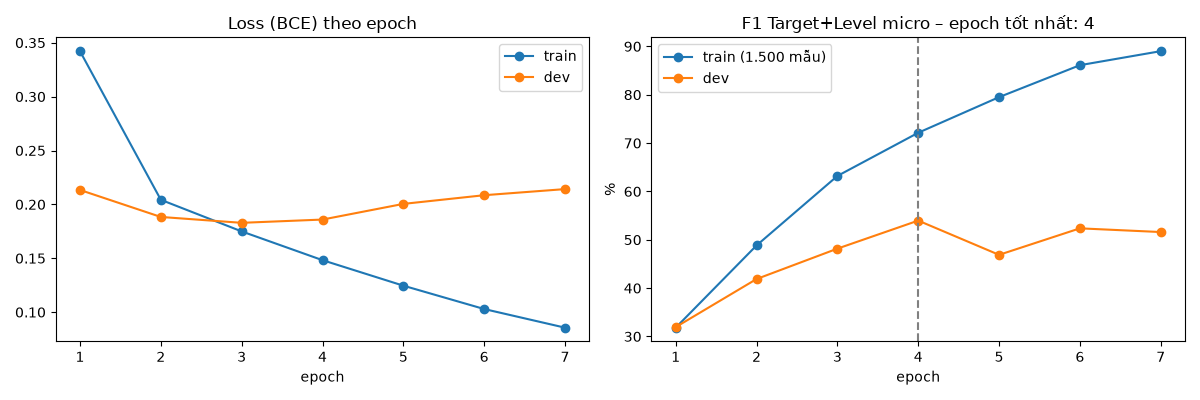

**PhoBERT-v2**

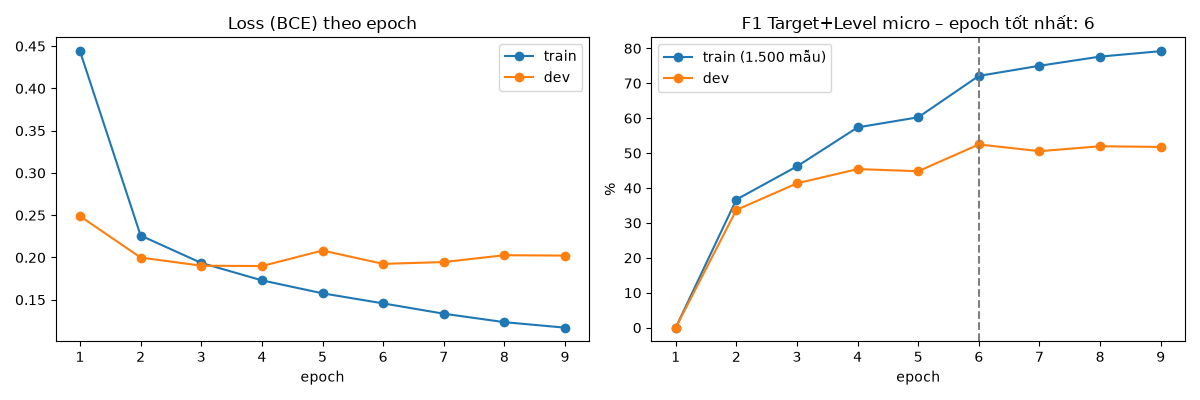

In [8]:
for key in loaded:
    p = OUT_DIR / f"{key}_learning_curve.png"
    if p.exists():
        display(Markdown(f"**{MODELS[key]}**")); display(Image(filename=str(p)))

## 8. Demo: dự đoán bình luận mới, 3 mô hình đặt cạnh nhau
Sửa danh sách câu trong ô dưới rồi chạy lại (Shift + Enter).

In [9]:
def demo(sentences):
    rows = []
    out = {"TF-IDF + LR": predict_baseline(sentences)[0]}
    for key, (model, tok, info) in loaded.items():
        out[MODELS[key]] = common.predict_transformer(model, tok, info, sentences, device=DEVICE, segmenter=segmenter)[0]
    for i, s in enumerate(sentences):
        for name, p in out.items():
            found = ", ".join(f"{TARGETS[j]}: {LEVELS[v]}" for j, v in enumerate(p[i]) if v > 0)
            rows.append({"bình luận": s, "mô hình": name, "kết quả": found or "không nhắc target nào"})
    with pd.option_context("display.max_colwidth", 80):
        display(pd.DataFrame(rows).set_index(["bình luận", "mô hình"]))

demo([
    "bài hát này hay quá, nghe hoài không chán",
    "thằng này ngu thật, nói chuyện như cc",
    "mấy người đó toàn lừa đảo, đừng tin",
    "chính phủ làm việc kém quá",
])

kết quả
bình luận                                 mô hình                                        
bài hát này hay quá, nghe hoài không chán TF-IDF + LR    individual: clean, groups: clean
                                          ViSoBERT       individual: clean, groups: clean
                                          PhoBERT-v2     individual: clean, groups: clean
thằng này ngu thật, nói chuyện như cc     TF-IDF + LR                    individual: hate
                                          ViSoBERT                       individual: hate
                                          PhoBERT-v2       individual: hate, groups: hate
mấy người đó toàn lừa đảo, đừng tin       TF-IDF + LR                   groups: offensive
                                          ViSoBERT       individual: clean, groups: clean
                                          PhoBERT-v2                không nhắc target nào
chính phủ làm việc kém quá                TF-IDF + LR  groups: clean, politics: offensive
                                          ViSoBERT       individual: clean, groups: clean
                                          PhoBERT-v2                    individual: clean

**Demo giao diện web (cũng offline):** mở cửa sổ dòng lệnh tại thư mục `local`, kích hoạt môi trường ảo, gõ `streamlit run app.py`,
rồi mở trình duyệt tại http://localhost:8501.